<a href="https://colab.research.google.com/github/Shashi-kumar-g/machine-learning-26/blob/main/Day06_shashi069.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Day 6 — Auto MPG Regression **The question I'm chasing:** if I only know a car's specs (weight, engine size, horsepower and so on), how close can ordinary linear regression get to its `mpg`? **House rules for today (from the Day 6 brief):**
- Split the data *first*, before I touch anything else.
- All cleaning lives inside a pipeline, so nothing sneaks across the train/test wall.
- `random_state=42` everywhere, and the same 5-fold shuffled KFold.
- Report three numbers: RMSE, MAE and R².
- Leave the car `name` column alone. Brand extraction is a Day 7 problem, and I'm not stealing tomorrow's work. > Reminder to future me: `auto_mpg.csv` has to sit next to this notebook. I *think* it's 398 rows x 9 columns with 6 missing horsepower values, but I'm going to check that instead of trusting my memory.


In [5]:
# Step 1: the usual toolbox, plus one seed so my results don't change every time I rerun
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

RANDOM_STATE = 42
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', None)


In [6]:
# Step 2: load the data, take a first look, and lock away a test set straight away
df = pd.read_csv('auto_mpg - auto_mpg.csv')
print(f'Dataset shape: {df.shape}  (I expected 398 x 9, so does that match?)')
display(df.head())

X = df.drop(columns=['mpg', 'name'])
y = df['mpg']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

print(f'Training rows: {len(X_train)} | Test rows (do not peek!): {len(X_test)}')


Dataset shape: (398, 9)  (I expected 398 x 9, so does that match?)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


Training rows: 318 | Test rows (do not peek!): 80


### Why I split before doing anything else
Say I filled in the missing horsepower using the average of the *whole* dataset. The test cars would have quietly helped decide that number, which is a little like peeking at the exam answers while writing the revision notes. The model's score would look better than it deserves. So the imputer and scaler only learn from training data, and the pipeline takes care of that for me, even inside each cross-validation fold.


In [7]:
# Step 3: a quick 'who's who' of the columns, plus a check on what's missing
# (this only documents things. Nothing is being fitted here.)
type_notes = {
    'mpg': 'Target: miles per gallon',
    'cylinders': 'Whole number: how many cylinders',
    'displacement': 'Continuous: engine size in cubic inches',
    'horsepower': 'Numeric: engine power. Has gaps, so it needs imputing',
    'weight': 'Numeric: weight in lbs',
    'acceleration': 'Numeric: seconds to reach 60 mph (smaller = quicker)',
    'model_year': 'Looks like a number, but really a year code (70 = 1970)',
    'origin': 'Category: USA / Europe / Japan, no natural order',
    'name': 'Free text. Parked until Day 7'
}
dictionary = pd.DataFrame({
    'column': df.columns,
    'pandas_dtype': [str(df[c].dtype) for c in df.columns],
    'missing_count': [int(df[c].isna().sum()) for c in df.columns],
    'what it is': [type_notes.get(c, 'Not sure yet, check this one') for c in df.columns]
})
display(dictionary)

print('Missing values, training rows only:')
display(X_train.isna().sum().rename('missing_in_training').to_frame())


,column,pandas_dtype,missing_count,what it is
0,mpg,float64,0,Target: miles per gallon
1,cylinders,int64,0,Whole number: how many cylinders
2,displacement,float64,0,Continuous: engine size in cubic inches
3,horsepower,float64,6,"Numeric: engine power. Has gaps, so it needs i..."
4,weight,int64,0,Numeric: weight in lbs
5,acceleration,float64,0,Numeric: seconds to reach 60 mph (smaller = qu...
6,model_year,int64,0,"Looks like a number, but really a year code (7..."
7,origin,object,0,"Category: USA / Europe / Japan, no natural order"
8,name,object,0,Free text. Parked until Day 7


Missing values, training rows only:


,missing_in_training
cylinders,0
displacement,0
horsepower,5
weight,0
acceleration,0
model_year,0
origin,0


**What I take from that table:** only `horsepower` has holes, so that's the only column that needs filling. I'm going with the **median** rather than the mean. A few monster engines would drag the mean upward, while the median just shrugs. It gets learned from each training fold and never from the full dataset. `origin` gets one-hot encoding. If I coded USA=1, Europe=2, Japan=3, the model would assume Japan is somehow "three times" USA, which makes no sense.


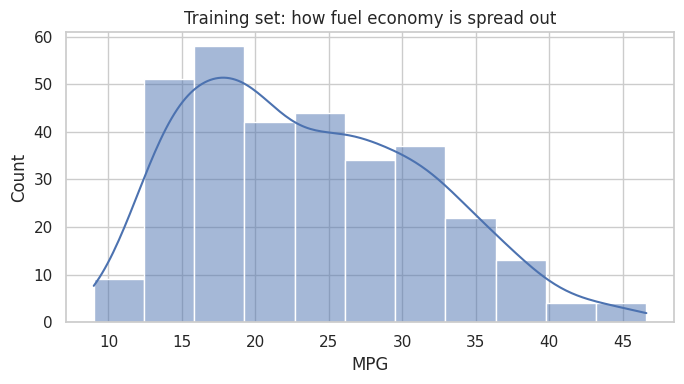

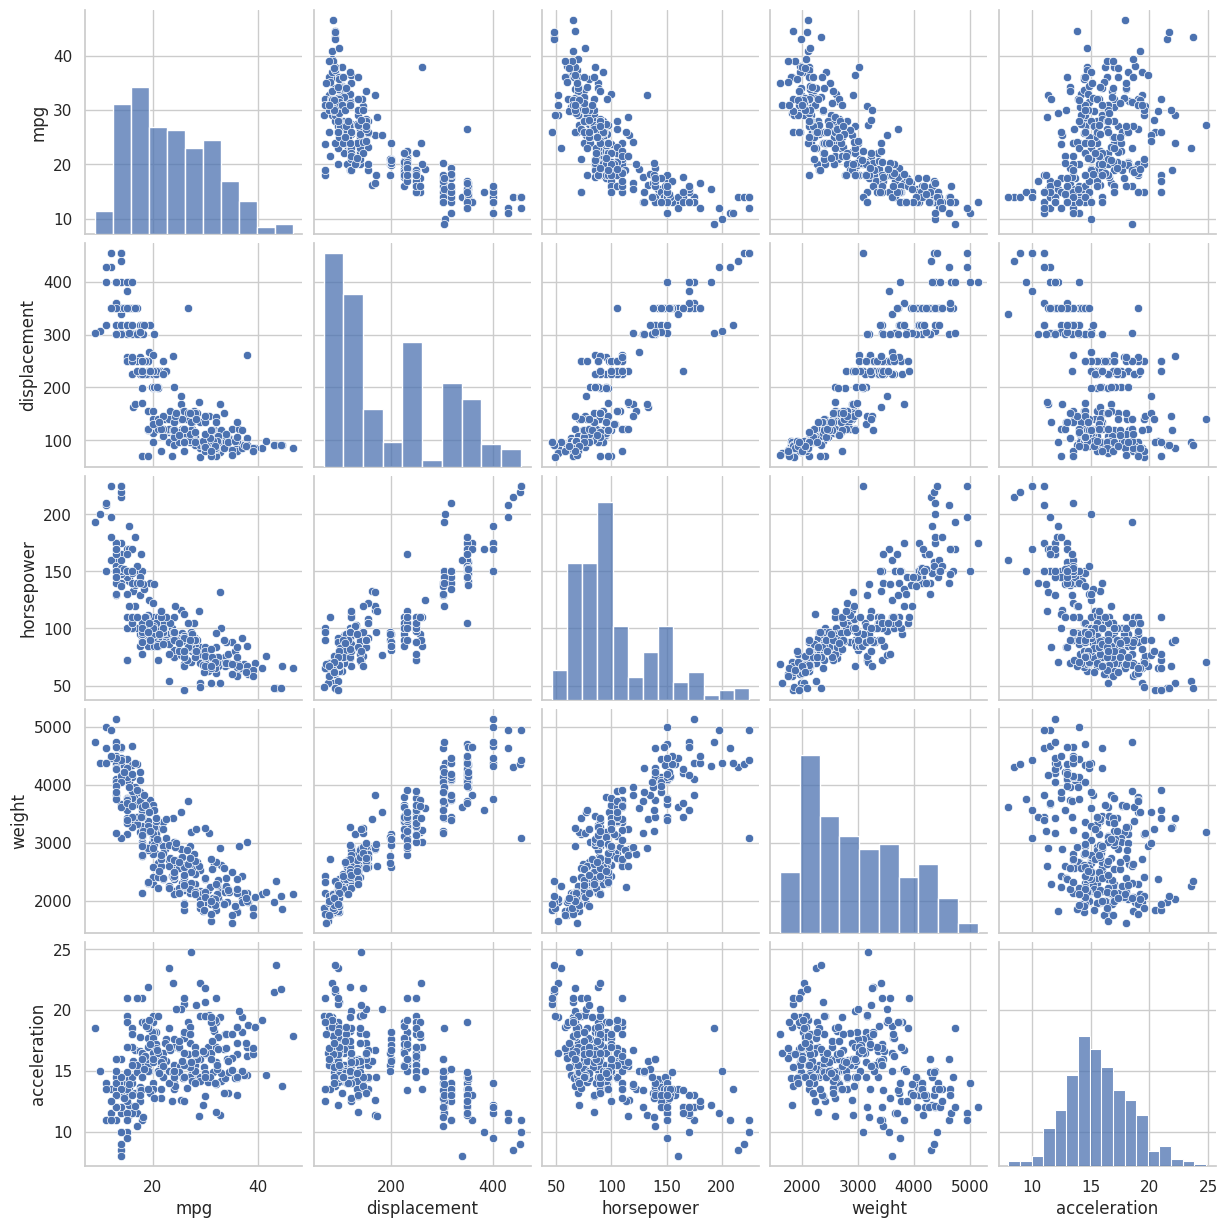

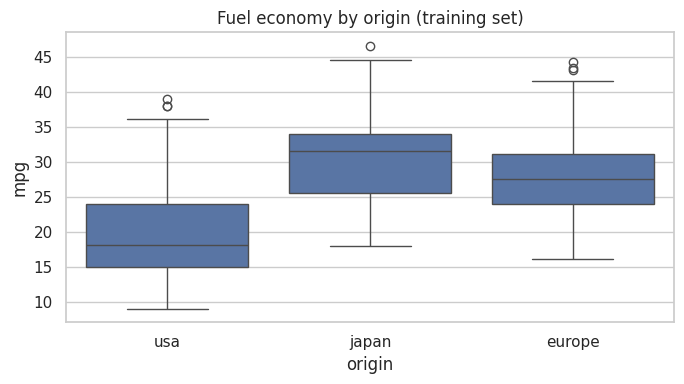

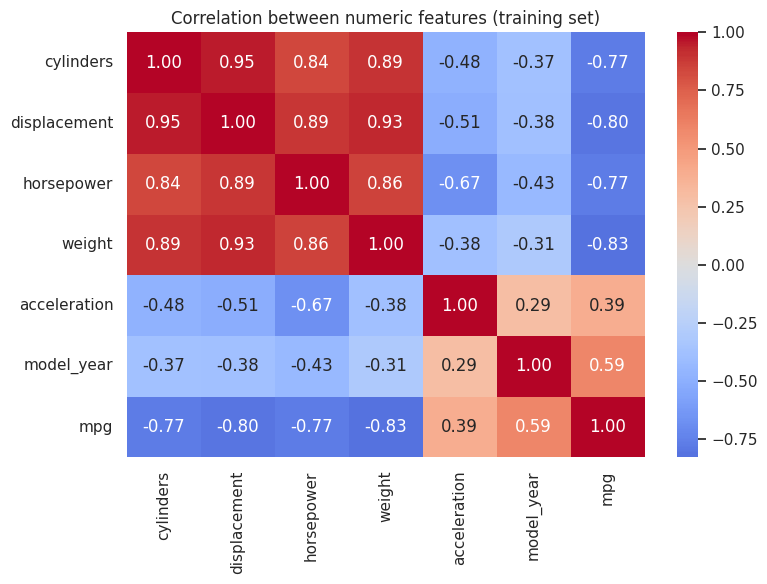

In [8]:
# Step 4: poking around. Plots use training rows only, so the test set stays a surprise
eda = X_train.copy()
eda['mpg'] = y_train

# 4a. What does fuel economy look like overall?
fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(data=eda, x='mpg', kde=True, ax=ax)
ax.set_title('Training set: how fuel economy is spread out')
ax.set_xlabel('MPG')
plt.tight_layout()
plt.show()

# 4b. Which specs move together with mpg?
sns.pairplot(eda[['mpg', 'displacement', 'horsepower', 'weight', 'acceleration']].dropna())
plt.show()

# 4c. Does where the car comes from matter?
fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=eda, x='origin', y='mpg', ax=ax)
ax.set_title('Fuel economy by origin (training set)')
plt.tight_layout()
plt.show()

# 4d. Who is related to whom?
fig, ax = plt.subplots(figsize=(8, 6))
corr = eda.select_dtypes(include='number').corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', center=0, fmt='.2f', ax=ax)
ax.set_title('Correlation between numeric features (training set)')
plt.tight_layout()
plt.show()


### What I noticed (rewrite these in my own words after looking at the real plots)
1. **The MPG histogram.** Is it one tidy hill or does it lean to one side? I'm looking for a long tail or two bumps, and I won't just assume it's a bell curve.
2. **Pair plot.** Heavier and bigger-engined cars *seem* to get worse mileage. That's good news for prediction, but it only shows the two go together and doesn't tell me one causes the other.
3. **Boxplot by origin.** The groups probably differ, but I can't say origin is the reason. Japanese cars in this data might simply be lighter and smaller.
4. **Heatmap.** `weight`, `displacement`, `horsepower` and `cylinders` look like close cousins. When inputs overlap this much, I shouldn't read too much into any single regression coefficient.
5. **Odd points.** Dots far outside the whiskers deserve a second look, but weird doesn't mean wrong. I'm not deleting anything without a real reason.


In [9]:
# Step 5: the baseline. Prep work and the model are bundled in one pipeline,
# so every fold re-learns its own median and scaling from its own training slice.
num_cols = ['cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model_year']
cat_cols = ['origin']

numeric_pipe = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
categorical_pipe = Pipeline(steps=[
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('numeric', numeric_pipe, num_cols),
    ('categorical', categorical_pipe, cat_cols)
])

baseline = Pipeline(steps=[
    ('preprocess', preprocessor),
    ('regression', LinearRegression())
])

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rmse = -cross_val_score(
    baseline, X_train, y_train, cv=cv, scoring='neg_root_mean_squared_error'
)
print('RMSE in each fold:', np.round(cv_rmse, 3))
print(f'Average CV RMSE: {cv_rmse.mean():.3f} mpg')
print(f'Spread (std) across folds: {cv_rmse.std():.3f} mpg')


RMSE in each fold: [3.6   3.798 3.263 3.188 3.539]
Average CV RMSE: 3.478 mpg
Spread (std) across folds: 0.224 mpg


In [10]:
# Step 6: the moment of truth. Train on all training rows, then score the untouched test set once.
def metric_report(model, X_eval, y_eval, label):
    prediction = model.predict(X_eval)
    return {
        'model': label,
        'RMSE (mpg)': np.sqrt(mean_squared_error(y_eval, prediction)),
        'MAE (mpg)': mean_absolute_error(y_eval, prediction),
        'R2': r2_score(y_eval, prediction)
    }

baseline.fit(X_train, y_train)
test_results = pd.DataFrame([metric_report(
    baseline, X_test, y_test, 'Linear regression baseline'
)])
display(test_results.round(3))


,model,RMSE (mpg),MAE (mpg),R2
0,Linear regression baseline,2.888,2.288,0.845


### Reading the scores like a human
- **MAE** is the one I'd tell a friend. On average the guess is off by this many mpg.
- **RMSE** is also in mpg, but it punishes big misses harder, so it's usually a bit higher than MAE. If it's *much* higher, a few cars are being predicted badly.
- **R²** says how much of the ups and downs in mpg the model explains compared with just guessing the average. It can even go negative if the model is worse than that.
- I'll compare CV RMSE with test RMSE. Similar numbers are reassuring, though a single split is still only one roll of the dice.


In [11]:
# Step 7: the four checkpoint questions, answered in my own words
answers = {
    '1. Why split before imputing?':
        'Because the fill-in value (the median) has to come from training data only. Otherwise test cars leak into the recipe, and the pipeline re-learns the median inside every fold to stop that.',
    '2. Why handle_unknown="ignore"?':
        'If a new row shows up with a category the encoder never saw while fitting, the encoder just gives it all zeros instead of crashing.',
    '3. Why does KNN care about scaling more than a decision tree?':
        'KNN literally measures distances, so a feature measured in thousands (weight) drowns out one measured in single digits. A tree only asks "is this value above or below a cut-off?", so the units do not matter to it.',
    '4. Does StandardScaler before LinearRegression change predictions or coefficients?':
        'The coefficients change because the features are now on different scales, and so does the intercept. The predictions stay the same, apart from tiny floating-point noise, because ordinary least squares finds the same fitted line either way.'
}
for question, answer in answers.items():
    display(Markdown(f'**{question}**  \n{answer}'))


**1. Why split before imputing?**  
Because the fill-in value (the median) has to come from training data only. Otherwise test cars leak into the recipe, and the pipeline re-learns the median inside every fold to stop that.

**2. Why handle_unknown="ignore"?**  
If a new row shows up with a category the encoder never saw while fitting, the encoder just gives it all zeros instead of crashing.

**3. Why does KNN care about scaling more than a decision tree?**  
KNN literally measures distances, so a feature measured in thousands (weight) drowns out one measured in single digits. A tree only asks "is this value above or below a cut-off?", so the units do not matter to it.

**4. Does StandardScaler before LinearRegression change predictions or coefficients?**  
The coefficients change because the features are now on different scales, and so does the intercept. The predictions stay the same, apart from tiny floating-point noise, because ordinary least squares finds the same fitted line either way.

In [12]:
# Step 8: don't just believe my answer to question 4. Test it.
# Same pipeline, but with the scaler removed.
numeric_pipe_unscaled = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])
pre_unscaled = ColumnTransformer(transformers=[
    ('numeric', numeric_pipe_unscaled, num_cols),
    ('categorical', OneHotEncoder(handle_unknown='ignore'), cat_cols)
])
baseline_unscaled = Pipeline(steps=[
    ('preprocess', pre_unscaled),
    ('regression', LinearRegression())
])
baseline_unscaled.fit(X_train, y_train)
pred_scaled = baseline.predict(X_test)
pred_unscaled = baseline_unscaled.predict(X_test)

print('Biggest gap between the two sets of predictions:',
      float(np.max(np.abs(pred_scaled - pred_unscaled))))
print('With scaling:')
display(pd.DataFrame([metric_report(baseline, X_test, y_test, 'Scaled')]).round(4))
print('Without scaling:')
display(pd.DataFrame([metric_report(baseline_unscaled, X_test, y_test, 'Unscaled')]).round(4))


Biggest gap between the two sets of predictions: 4.3520742565306136e-13
With scaling:


,model,RMSE (mpg),MAE (mpg),R2
0,Scaled,2.8877,2.2882,0.8449


Without scaling:


,model,RMSE (mpg),MAE (mpg),R2
0,Unscaled,2.8877,2.2882,0.8449


In [13]:
# Step 9 (stretch): does a little regularisation help? Ridge, same prep, same folds.
ridge = Pipeline(steps=[
    ('preprocess', preprocessor),
    ('regression', Ridge(alpha=1.0))
])
ridge_cv_rmse = -cross_val_score(
    ridge, X_train, y_train, cv=cv, scoring='neg_root_mean_squared_error'
)
print(f'Linear regression, average CV RMSE: {cv_rmse.mean():.3f} mpg')
print(f'Ridge, average CV RMSE:             {ridge_cv_rmse.mean():.3f} mpg')
print('Rule for myself: pick using CV scores, and stop checking the test set to see who wins.')


Linear regression, average CV RMSE: 3.478 mpg
Ridge, average CV RMSE:             3.471 mpg
Rule for myself: pick using CV scores, and stop checking the test set to see who wins.
